In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
import scipy.odr as odr

# Elastizität

## Aufgabe 1

### Ziel: Bestimmung der Durchbiegung als Funktion der angehängten Last von 4 Metallstäben

### Gemessen: 
        - Biegung der Metallstäbe und die dafür verantwortliche Masse
            - 4 Stäbe, einer davon lange Seite und kurze Seite unten
            - Biegung für 5 verschiedene Massen
        - Durchmesser der Stäbe
            - 5 verschiedene Stellen a 3 mal
### Formel:
Mit der Formel 
$$
h_{max} = \frac{F}{E \cdot I_q} \frac{L^3}{3} \Leftrightarrow h_{max} = k \cdot F
$$
mit
$$
k = \frac{1}{E \cdot I_q} \frac{L^3}{3} \Leftrightarrow E = \frac{1}{k \cdot I_q} \frac{L^3}{3}
$$
kommt man an $E$, wobei $F$ ist $F_G = m\cdot g$, $E$ ist das Elastizitätsmodul
$k$ ist Proportionalitätskonstante zwischen $h_{max}$ und $F$ und ist dabei konstant
$I_q$ für kreisförmiger Querschnitt:
$$
I_{Kreis} = \frac{\pi d^4}{64}
$$
$I_q$ für rechteckiger Querschnitt:
$$
I_{Rechteck} = \frac{ a b^3}{12}
$$
wobei a senkrecht zur Biegungsebene ist.
### Vorgehen:
- Werte für Masse gegen Höhe die durch die Biegung entsteht plotten
- fit erstellen
- Steigung ist k, worüber sich das Elastizitätsmodul berechnen lässt 

### Unsicherheiten
- E ist von den unsicherheitsbelasteten Größen $h_{max}$, $I_q$ und $k$ abhängig 
- die Unsicherheit des Flächenträgheitsmoments $I_q$ ist durch die Unsicherheit in dem Durchmesser gegeben
$$
u_{I_{q, zyl}} = \frac{\pi d^3}{16}\cdot u_{d}
$$

$$
u_{I_{q, qua}} = \sqrt{\left( \frac{b^3}{12} \cdot u_a \right)^2 + \left( \frac{ a b^2}{4} u_b\right)^2}
$$

$$
u_E = \sqrt{\left(- \frac{1}{k^2 \cdot I_q} \frac{L^3}{3} u_k \right)^2 + \left( \frac{1}{k \cdot I_q ^2} \frac{L^3}{3} u_{I_q} \right)^2 + \left( \frac{1}{k \cdot I_q} L^2 u_L \right)^2}
$$

$\Leftrightarrow$

$$
u_E = \sqrt{\left(- \frac{E}{k} u_k \right)^2 + \left( \frac{E}{I_q} u_{I_q} \right)^2 + \left( \frac{1}{k \cdot I_q} L^2 u_L \right)^2}
$$

In [3]:
# Unsicherheiten Messgeräte
u_sch = (0.01*1e-3)/2*np.sqrt(6) # in m mit Dreiecksverteilung
print(u_sch)
g = 9.81

1.224744871391589e-05


In [4]:
def elas(k, I, L):
    temp = (L**3)/(3*k*I)
    return temp

In [5]:
def u_elas(k, u_k, I, u_I, L, u_L):
    temp = ((L**3 * u_k)/(k**2 * I *3))**2
    temp1 = ((L**3 * u_I)/(k* I**2 *3))**2
    temp2 = ((L**2 * u_L)/(k*I))**2
    return np.sqrt(temp + temp1 + temp2)

In [6]:
def u_I_qua(a, u_a, b, u_b):
    temp1 = ((b**3 * u_a)/12)**2
    temp2 = ((a* b**2 * u_b)/4)**2
    return np.sqrt(temp1 + temp2)

In [7]:
# Masse
m_array = np.array([5, 40, 80, 120, 160])*1e-3
F_array = m_array*g

In [8]:
def gerade(x, m, c):
    return m*x + c

### Goldfarbener Quader

In [9]:
# Werte Durchmesser
d_gold_qua_k_array = (np.array([1.97, 1.97, 1.97, 1.98, 1.98, 1.98, 1.97, 1.98, 1.97, 1.98, 1.98, 1.99, 1.98, 1.99, 1.98])+0.01)*1e-3 # in m
d_gold_qua_l_array = (np.array([4.99, 4.98, 4.98, 4.98, 4.98, 4.98, 4.98, 4.98, 4.98, 4.98, 4.98, 4.98, 4.98, 4.98, 4.99, 4.98, 4.98, 4.99, 4.98, 4.98, 4.99])+0.01)*1e-3 # in m
d_std_gold_qua_k = d_gold_qua_k_array.std(ddof=1)/np.sqrt(len(d_gold_qua_k_array))
d_std_gold_qua_l = d_gold_qua_l_array.std(ddof=1)/np.sqrt(len(d_gold_qua_l_array))
d_gold_qua_k = d_gold_qua_k_array.mean()
d_gold_qua_l = d_gold_qua_l_array.mean()

# direkt kombinierte Unsicherheit wegen Messgerät
u_d_gold_qua_k = np.sqrt(d_std_gold_qua_k**2 + u_sch**2)
u_d_gold_qua_l = np.sqrt(d_std_gold_qua_l**2 + u_sch**2)

# Länge des Stabes 
l_gold_qua = 0.294 # in m
u_l_gold_qua = 0.001/(2*np.sqrt(6)) # in m und Dreiecksverteilung, Maßband

print("Durchmesser goldfarbener Quader kurze Seite: " + str(d_gold_qua_k*1e3) + " +/- " + str(u_d_gold_qua_k*1e3)) 
print("Durchmesser goldfarbener Quader lange Seite: " + str(d_gold_qua_l*1e3) + " +/- " + str(u_d_gold_qua_l*1e3))
print()
print("Der Stab ist " + str(l_gold_qua*1e2) + " +/- " + str(u_l_gold_qua*1e2) + " m lang")
print()
print(u_l_gold_qua)

Durchmesser goldfarbener Quader kurze Seite: 1.9879999999999993 +/- 0.012371241613016015
Durchmesser goldfarbener Quader lange Seite: 4.991904761904762 +/- 0.012278883298439206

Der Stab ist 29.4 +/- 0.020412414523193156 m lang

0.00020412414523193154


In [10]:
# Flächenträgheitsmomente
I_qua_st = d_gold_qua_k*d_gold_qua_l**3/12 # Stab "stehend", also kurze Seite unten, also a = gold_qua_k, ergo hochkant eingespannt
I_qua_li = d_gold_qua_l*d_gold_qua_k**3/12 # Stab "liegend", also lange Seite unten, also a = gold_qua_l, ergo flachkant eingespannt
u_I_qua_st = u_I_qua(d_gold_qua_k, u_d_gold_qua_k, d_gold_qua_l, u_d_gold_qua_l)
u_I_qua_li = u_I_qua(d_gold_qua_l, u_d_gold_qua_l, d_gold_qua_k, u_d_gold_qua_k)
print("Flächenträgheitsmoment Quader stehend: " + str(I_qua_st) + " +/- " + str(u_I_qua_st))
print("Flächenträgheitsmoment Quader liegend: " + str(I_qua_li) + " +/- " + str(u_I_qua_li))

Flächenträgheitsmoment Quader stehend: 2.0607912761319475e-11 +/- 1.9892662221844147e-13
Flächenträgheitsmoment Quader liegend: 3.2683923491022196e-12 +/- 6.154455987877829e-14


In [11]:
# Werte für Durchbiegung und Masse
"""
Bei der Duchbiegung: Differenz zwischen Nullpunkt und Auslenkung. Bereits in den folgenden Daten vorhanden. 
Die Auslenkung wurde von einer Zentimeterskala abgelesen, die auf Millimeter genau war
"""
u_skala = 0.001/(2*np.sqrt(6)) # in m und Dreiecksverteilung

# hochkant eingespannt
a_gold_qua_h_array = np.array([0, 0.1, 0.3, 0.5, 0.7])*1e-2 

# flachkant eingespannt
a_gold_qua_f_array = np.array([0.1, 1.1, 2.2, 3.2, 4.3])*1e-2

In [12]:
# Fit hochkant
opt_qua_h, cov_qua_h = optimize.curve_fit(gerade, F_array, a_gold_qua_h_array, sigma=u_skala * np.ones_like(a_gold_qua_h_array),
                              absolute_sigma=True)
m_qua_h, c_qua_h = opt_qua_h
u_m_qua_h, u_c_qua_h = np.sqrt(np.diag(cov_qua_h))
print("Die Steigung beträgt: " + str(m_qua_h) + " +/- " + str(u_m_qua_h))
print("Der y-Achsenabschnitt beträgt: " + str(c_qua_h) + " +/- " + str(u_c_qua_h))

Die Steigung beträgt: 0.004715079276120909 +/- 0.00016866231312997795
Der y-Achsenabschnitt beträgt: -0.0005466491425248631 +/- 0.000162157014753335


In [13]:
# Fit flachkant
opt_qua_f, cov_qua_f = optimize.curve_fit(gerade, F_array, a_gold_qua_f_array, sigma=u_skala * np.ones_like(a_gold_qua_f_array),
                              absolute_sigma=True)
m_qua_f, c_qua_f = opt_qua_f
u_m_qua_f, u_c_qua_f = np.sqrt(np.diag(cov_qua_f))
print("Die Steigung beträgt: " + str(m_qua_f) + " +/- " + str(u_m_qua_f))
print("Der y-Achsenabschnitt beträgt: " + str(c_qua_f) + " +/- " + str(u_c_qua_f))

Die Steigung beträgt: 0.0274331886967093 +/- 0.0001686739683462833
Der y-Achsenabschnitt beträgt: 1.307878754741587e-06 +/- 0.00016216052451692157


In [14]:
# Elastizität
E_gold_qua_h = elas(m_qua_h, I_qua_st, l_gold_qua)
u_E_gold_qua_h = u_elas(m_qua_h, u_m_qua_h, I_qua_st, u_I_qua_st, l_gold_qua, u_l_gold_qua)
print("Das Elastizitätsmodul E für den hochkant eingespannten goldfarbener Stab lautet: " + str(E_gold_qua_h*1e-9) + " +/- " + str(u_E_gold_qua_h*1e-9))
print("rel. Unsicherheit: " +str(u_E_gold_qua_h/E_gold_qua_h))
print()
E_gold_qua_f = elas(m_qua_f, I_qua_li, l_gold_qua)
u_E_gold_qua_f = u_elas(m_qua_f, u_m_qua_f, I_qua_li, u_I_qua_li, l_gold_qua, u_l_gold_qua)
print("Das Elastizitätsmodul E für den flachkant eingespannten goldfarbener Stab lautet: " + str(E_gold_qua_f*1e-9) + " +/- " + str(u_E_gold_qua_f*1e-9))
print("rel. Unsicherheit: " +str(u_E_gold_qua_f/E_gold_qua_f))

Das Elastizitätsmodul E für den hochkant eingespannten goldfarbener Stab lautet: 87.17615905085997 +/- 3.235010720984585
rel. Unsicherheit: 0.03710889257115845

Das Elastizitätsmodul E für den flachkant eingespannten goldfarbener Stab lautet: 94.47355556084409 +/- 1.881709063394264
rel. Unsicherheit: 0.019917838936234184


### Goldfarbener Zylinder

In [15]:
# Werte Durchmesser
d_gold_zyl_array = (np.array([2.96, 2.96, 2.96, 2.96, 2.97, 2.96, 2.97, 2.97, 2.97, 2.97, 2.98, 2.97, 2.97, 2.97, 2.96])+0.01)*1e-3 # in m
d_std_gold_zyl = d_gold_zyl_array.std(ddof=1)/np.sqrt(len(d_gold_zyl_array))
d_gold_zyl = d_gold_zyl_array.mean()

# direkt kombinierte Unsicherheit wegen Messgerät
u_d_gold_zyl = np.sqrt(d_std_gold_zyl**2 + u_sch**2)

print("Durchmesser goldfarbener Zylinder: " + str(d_gold_zyl*1e3) + " +/- " + str(u_d_gold_zyl*1e3)) 
print("rel. U: " +str(u_d_gold_zyl/d_gold_zyl))
# Länge des Stabes 
l_gold_zyl = 0.291 # in m
u_l_gold_zyl = 0.001/(2*np.sqrt(6)) # in m und Dreiecksverteilung, Maßband
print("Der Stab ist " + str(l_gold_zyl*1e2) + " +/- " + str(u_l_gold_zyl*1e2) + " m lang")
print("rel. U: " + str(u_l_gold_zyl/ l_gold_zyl))
# Flächenträgheitsmomente
I_gold_zyl = (np.pi * d_gold_zyl**4)/64
u_I_gold_zyl = (np.pi * d_gold_zyl**3 * u_d_gold_zyl)/16

print("Flächenträgheitsmoment goldfarbener Zylinder : " + str(I_gold_zyl) + " +/- " + str(u_I_gold_zyl))

Durchmesser goldfarbener Zylinder: 2.9766666666666666 +/- 0.012350695629788735
rel. U: 0.004149169864430706
Der Stab ist 29.099999999999998 +/- 0.020412414523193156 m lang
rel. U: 0.0007014575437523421
Flächenträgheitsmoment goldfarbener Zylinder : 3.853813692041028e-12 +/- 6.39605105365883e-14


In [16]:
# Eingespannt
a_gold_zyl_array = np.array([0.1, 0.6, 1.2, 2.6, 3.5])*1e-2

# Fit goldfabiger zylinder 
opt_gold_zyl, cov_gold_zyl = optimize.curve_fit(gerade, F_array, a_gold_zyl_array, sigma=u_skala * np.ones_like(a_gold_zyl_array),
                              absolute_sigma=True)
m_gold_zyl, c_gold_zyl = opt_gold_zyl
u_m_gold_zyl, u_c_gold_zyl = np.sqrt(np.diag(cov_gold_zyl))
print("Die Steigung beträgt: " + str(m_gold_zyl) + " +/- " + str(u_m_gold_zyl))
print("Der y-Achsenabschnitt beträgt: " + str(c_gold_zyl) + " +/- " + str(u_c_gold_zyl))

Die Steigung beträgt: 0.023073079648755865 +/- 0.0001686623161385601
Der y-Achsenabschnitt beträgt: -0.002334099794171232 +/- 0.00016215701724937867


In [17]:
E_gold_zyl = elas(m_gold_zyl, I_gold_zyl, l_gold_zyl)
u_E_gold_zyl = u_elas(m_gold_zyl, u_m_gold_zyl, I_gold_zyl, u_I_gold_zyl, l_gold_zyl, u_l_gold_zyl)
print("Das Elastizitätsmodul E für den zylinderförmiger goldfarbener Stab lautet: " + str(E_gold_zyl*1e-9) + " +/- " + str(u_E_gold_zyl*1e-9))
print("rel. Unsicherheit: " +str(u_E_gold_zyl/E_gold_zyl))

Das Elastizitätsmodul E für den zylinderförmiger goldfarbener Stab lautet: 92.37648470495681 +/- 1.6865048387363946
rel. Unsicherheit: 0.01825686314133903


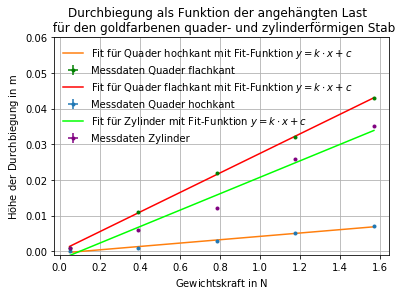

In [18]:
plt.figure()
# hochkant
plt.errorbar(F_array, a_gold_qua_h_array, xerr = 0, yerr= u_skala, fmt=".", label = "Messdaten Quader hochkant")
plt.plot(F_array, gerade(F_array, m_qua_h, c_qua_h), label = "Fit für Quader hochkant mit Fit-Funktion $y = k\cdot x + c$")
# flachkant
plt.errorbar(F_array, a_gold_qua_f_array, xerr = 0, yerr= u_skala, fmt=".", label = "Messdaten Quader flachkant", color = "green")
plt.plot(F_array, gerade(F_array, m_qua_f, c_qua_f), label = "Fit für Quader flachkant mit Fit-Funktion $y = k\cdot x + c$ ", color = "red")
# zylinder
plt.errorbar(F_array, a_gold_zyl_array, xerr = 0, yerr= u_skala, fmt=".", label = "Messdaten Zylinder", color = 'purple')
plt.plot(F_array, gerade(F_array, m_gold_zyl, c_gold_zyl), label = "Fit für Zylinder mit Fit-Funktion $y = k\cdot x + c$ ", color = 'lime')

plt.ylim(-0.001, 0.06)

handles, labels = plt.gca().get_legend_handles_labels()
#specify order of items in legend
order = [0, 4, 1, 3, 2, 5]

plt.grid()
plt.ylabel("Höhe der Durchbiegung in $\mathrm{m}$")
plt.xlabel("Gewichtskraft in $\mathrm{N}$")
plt.title("Durchbiegung als Funktion der angehängten Last  \n für den goldfarbenen quader- und zylinderförmigen Stab")
plt.legend( [handles[idx] for idx in order],[labels[idx] for idx in order], loc = "upper left", frameon=False)
plt.savefig('Durchbiegung als Funktion der angehängten Last für den goldfarbener hoch- und flachkant eingespannten Quader.pdf')

### SilberfarbenerZylinder

In [19]:
# Werte Durchmesser
d_silber_zyl_array = (np.array([2.98, 2.98, 2.98, 2.98, 2.98, 2.98, 2.99, 2.98, 2.99, 2.99, 2.98, 2.98, 2.96, 2.96, 2.96])+0.01)*1e-3 # in m
d_std_silber_zyl = d_silber_zyl_array.std(ddof=1)/np.sqrt(len(d_silber_zyl_array))
d_silber_zyl = d_silber_zyl_array.mean()

# direkt kombinierte Unsicherheit wegen Messgerät
u_d_silber_zyl = np.sqrt(d_std_silber_zyl**2 + u_sch**2)

print("Durchmesser silberfarbener Zylinder: " + str(d_silber_zyl*1e3) + " +/- " + str(u_d_silber_zyl*1e3)) 
print("rel. Unsicherheit: " +str((u_d_silber_zyl*1e3)/(d_silber_zyl*1e3)))

# Länge des Stabes 
l_silber_zyl = 0.290 # in m
u_l_silber_zyl = 0.001/(2*np.sqrt(6)) # in m und Dreiecksverteilung, Maßband
print("Der Stab ist " + str(l_silber_zyl*1e2) + " +/- " + str(u_l_silber_zyl*1e2) + " m lang")
print("rel U: " +str(u_l_silber_zyl/l_silber_zyl))

# Flächenträgheitsmomente
I_silber_zyl = (np.pi * d_silber_zyl**4)/64
u_I_silber_zyl = (np.pi * d_silber_zyl**3 * u_d_silber_zyl)/16

print("Flächenträgheitsmoment silberfarbener Zylinder : " + str(I_silber_zyl) + " +/- " + str(u_I_silber_zyl))

Durchmesser silberfarbener Zylinder: 2.988 +/- 0.012524262168173535
rel. Unsicherheit: 0.004191520136604262
Der Stab ist 28.999999999999996 +/- 0.020412414523193156 m lang
rel U: 0.0007038763628687295
Flächenträgheitsmoment silberfarbener Zylinder : 3.912841637613655e-12 +/- 6.560301806160493e-14


In [20]:
# Eingespannt
a_silber_zyl_array = np.array([0.1, 1.2, 2.4, 3.4, 4.5])*1e-2

# Fit silberfabiger zylinder 
opt_silber_zyl, cov_silber_zyl = optimize.curve_fit(gerade, F_array, a_silber_zyl_array, sigma=u_skala * np.ones_like(a_silber_zyl_array),
                              absolute_sigma=True)
m_silber_zyl, c_silber_zyl = opt_silber_zyl
u_m_silber_zyl, u_c_silber_zyl = np.sqrt(np.diag(cov_silber_zyl))
print("Die Steigung beträgt: " + str(m_silber_zyl) + " +/- " + str(u_m_silber_zyl))
print("Der y-Achsenabschnitt beträgt: " + str(c_silber_zyl) + " +/- " + str(u_c_silber_zyl))

Die Steigung beträgt: 0.028725816516344614 +/- 0.000168662276583913
Der y-Achsenabschnitt beträgt: 0.00037417904281011237 +/- 0.00016215699278742418


In [21]:
E_silber_zyl = elas(m_silber_zyl, I_silber_zyl, l_silber_zyl)
u_E_silber_zyl = u_elas(m_silber_zyl, u_m_silber_zyl, I_silber_zyl, u_I_silber_zyl, l_silber_zyl, u_l_silber_zyl)
print("Das Elastizitätsmodul E für den silberfarbener Stab lautet: " + str(E_silber_zyl*1e-9) + " +/- " + str(u_E_silber_zyl*1e-9))
print("rel. Unsicherheit: " +str(u_E_silber_zyl/E_silber_zyl))

Das Elastizitätsmodul E für den silberfarbener Stab lautet: 72.32827135109846 +/- 1.2939169789467189
rel. Unsicherheit: 0.017889505096364614


### Bleifarbener Zylinder

In [22]:
# Werte Durchmesser
d_blei_zyl_array = (np.array([2.98, 2.98, 2.98, 2.99, 2.99, 2.99, 2.98, 2.99, 2.98, 2.99, 2.99, 2.99, 2.99, 2.99, 2.99])+0.01)*1e-3 # in m
d_std_blei_zyl = d_blei_zyl_array.std(ddof=1)/np.sqrt(len(d_blei_zyl_array))
d_blei_zyl = d_blei_zyl_array.mean()

# direkt kombinierte Unsicherheit wegen Messgerät
u_d_blei_zyl = np.sqrt(d_std_blei_zyl**2 + u_sch**2)

print("Durchmesser bleifarbener Zylinder: " + str(d_blei_zyl*1e3) + " +/- " + str(u_d_blei_zyl*1e3)) 
print("rel U: " +str(u_d_blei_zyl/d_blei_zyl))
# Länge des Stabes 
l_blei_zyl = 0.281 # in m
u_l_blei_zyl = 0.001/(2*np.sqrt(6)) # in m und Dreiecksverteilung, Maßband
print("Der Stab ist " + str(l_blei_zyl*1e2) + " +/- " + str(u_l_blei_zyl*1e2) + " m lang")
print("rel u: " + str(u_l_blei_zyl/l_blei_zyl))
# Flächenträgheitsmomente
I_blei_zyl = (np.pi * d_blei_zyl**4)/64
u_I_blei_zyl = (np.pi * d_blei_zyl**3 * u_d_blei_zyl)/16

print("Flächenträgheitsmoment bleifarbener Zylinder : " + str(I_blei_zyl) + " +/- " + str(u_I_blei_zyl))

Durchmesser bleifarbener Zylinder: 2.9966666666666675 +/- 0.012312079498902758
rel U: 0.0041085916014136
Der Stab ist 28.1 +/- 0.020412414523193156 m lang
rel u: 0.0007264204456652368
Flächenträgheitsmoment bleifarbener Zylinder : 3.958436174143715e-12 +/- 6.50543904792746e-14


In [23]:
# Eingespannt
a_blei_zyl_array = np.array([0, 0.4, 0.9, 1.3, 1.7])*1e-2

# Fit bleifabiger zylinder 
opt_blei_zyl, cov_blei_zyl = optimize.curve_fit(gerade, F_array, a_blei_zyl_array, sigma=u_skala * np.ones_like(a_blei_zyl_array),
                              absolute_sigma=True)
m_blei_zyl, c_blei_zyl = opt_blei_zyl
u_m_blei_zyl, u_c_blei_zyl = np.sqrt(np.diag(cov_blei_zyl))
print("Die Steigung beträgt: " + str(m_blei_zyl) + " +/- " + str(u_m_blei_zyl))
print("Der y-Achsenabschnitt beträgt: " + str(c_blei_zyl) + " +/- " + str(u_c_blei_zyl))

Die Steigung beträgt: 0.011231801153280117 +/- 0.00016866231839763755
Der y-Achsenabschnitt beträgt: -0.0003249015463703602 +/- 0.00016215702302895945


In [24]:
E_blei_zyl = elas(m_blei_zyl, I_blei_zyl, l_blei_zyl)
u_E_blei_zyl = u_elas(m_blei_zyl, u_m_blei_zyl, I_blei_zyl, u_I_blei_zyl, l_blei_zyl, u_l_blei_zyl)
print("Das Elastizitätsmodul E für den bleifarbener Stab lautet: " + str(E_blei_zyl*1e-9) + " +/- " + str(u_E_blei_zyl*1e-9))
print("rel. Unsicherheit: " +str(u_E_blei_zyl/E_blei_zyl))

Das Elastizitätsmodul E für den bleifarbener Stab lautet: 166.35070742119603 +/- 3.7209525703848434
rel. Unsicherheit: 0.022368119908041512


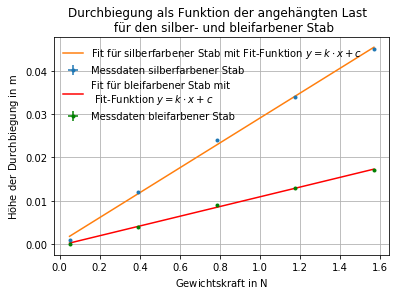

In [25]:
plt.figure()
# silber
plt.errorbar(F_array,  a_silber_zyl_array, xerr = 0, yerr= u_skala, fmt=".", label = "Messdaten silberfarbener Stab")
plt.plot(F_array, gerade(F_array, m_silber_zyl, c_silber_zyl), label = "Fit für silberfarbener Stab mit Fit-Funktion $y = k\cdot x + c$")
# blei
plt.errorbar(F_array, a_blei_zyl_array, xerr = 0, yerr= u_skala, fmt=".", label = "Messdaten bleifarbener Stab", color = "green")
plt.plot(F_array, gerade(F_array, m_blei_zyl, c_blei_zyl), label = "Fit für bleifarbener Stab mit \n Fit-Funktion $y = k\cdot x + c$ ", color = "red")

#plt.ylim(-0.001, 0.06)

handles, labels = plt.gca().get_legend_handles_labels()
#specify order of items in legend
order = [0, 2, 1, 3]

plt.grid()
plt.ylabel("Höhe der Durchbiegung in $\mathrm{m}$")
plt.xlabel("Gewichtskraft in $\mathrm{N}$")
plt.title("Durchbiegung als Funktion der angehängten Last  \n für den silber- und bleifarbener Stab")
plt.legend( [handles[idx] for idx in order],[labels[idx] for idx in order], loc = "upper left", frameon=False)
plt.savefig('Durchbiegung als Funktion der angehängten Last für den silber- und bleifarbenen Stab.pdf')

## Aufgabe 2 - Bestimmung Schubmodul

### Gemessen: 
    - 3 x 3 Messungen der Schwingungsdauer 
    - Länge des Drahtes
    - Masse der Scheibe
    - Druchmesser der Scheibe
    - Durchmesser des Drahtes
   
### Formeln:  
$$
G = \frac{8\pi L J_z}{R^4 T^2} = \frac{4\pi L m_z R^2_z}{R^4 T^2}
$$

G Schubmodul, L Lände des Drahtes, m_z Masse der Scheibe, R_z Radius Schreibe, R Radius Draht, T Schwingungsperiode

### Vorgehen: 
- alle Größen außer T bekannt, Bestwert duch 3
- aus den drei Perioden mitteln
- Mittelwert Durchmesser des Drahtes, umrechnen in Raidus
- Durchmesser Scheibe in Radius

### Unsicherheiten:
- Schwingungsdauer: 
    - Reaktionzeit: 0.3 Sekunden -> 300 Millisekunden + Dreiecksverteilung
    - Ablesegenauigkeit Stoppuhr: a = 0.01 s + Rechtecksverteilung 
    - Standardunsicherheit der Mittelwerte berechnen, zusätzlich Student'sche T-Verteilung
    - direkt kombinierte Unsicherheit mit den drei genannten Aspekten
- Durchmessre Draht:
    - Standardunsicherheit der Mittelwerte
    - Ablesegenauigkeit Schraube: a = 0.01mm + Dreiecksverteilung 
    - Unsicherheit für Radius: $u_r = 0.5 \cdot u_d$ 
- Länge Draht:
    - Ablesegenauigkeit Maßband: a = 0.001 m + Dreiecksverteilung 
- Durchmesser Scheibe:
    - Ablesegenauigkeit Schraube: a = 0.01mm + Dreiecksverteilung 
    - Unsicherheit für Radius: $u_r = 0.5 \cdot u_d$
- Masse: keine Unsicherheit
- Schubmodul: Fehlerfortpflanzun
$$
u_G = \sqrt{\left( \frac{4\pi  m_z R^2_z}{R^4 T^2} \cdot u_L \right)^2 + \left( \frac{8\pi L m_z R_z}{R^4 T^2} \cdot u_{R_z} \right)^2 + \left( -\frac{16 \pi L m_z R^2_z}{R^5 T^2} \cdot u_R \right)^2 +\left( -\frac{8\pi L m_z R^2_z}{R^4 T^3} \cdot u_{T} \right)^2}
$$

In [26]:
# Messdaten Schwingungsdauer
T_3_1 = 60000 + 29000 + 590 # in ms
T_3_2 = 60000 + 30000 + 30 # in ms
T_3_3 = 60000 + 29000 + 780 # in ms
T_3_array = np.array([T_3_1, T_3_2, T_3_3])/1000
T_array = T_3_array/3
T_0 = T_array.mean()
print(str(T_0) + "ist die Schwingungsdauer in Sek")

# Unsicherheit
u_reak = 0.3/(2*np.sqrt(6))
u_ablese = 0.01/(2*np.sqrt(6))
u_T_0_std_corr = (T_array.std(ddof=1)/np.sqrt(3))*1.32
u_T_0 = np.sqrt(u_reak**2 + u_ablese**2 + u_T_0_std_corr**2)
print(str(u_T_0) + "ist die Unsicherheit der Schwingungsdauer in Sek")

# Messdaten Durchmesser Draht
d_draht_array = (np.array([0.51, 0.51, 0.52, 0.51, 0.51, 0.51, 0.51, 0.51, 0.51, 0.51, 0.51, 0.51, 0.51, 0.51, 0.50])+0.01)*1e-3 # in m
d_draht = d_draht_array.mean()
r_draht = d_draht/2

# Unsicherheit
u_d_draht_std = d_draht_array.std(ddof=1)
u_d_draht = np.sqrt(u_sch**2 + u_d_draht_std**2)
u_r_draht = u_d_draht/2

print("Radius Draht: "+ str(r_draht) + " +/- " + str(u_r_draht) + " in Meter")

# Messdaten länge Draht
l_draht = 1.705 # in m
u_l_draht = 0.001/(2*np.sqrt(6))
print("Drahtlänge: " +str(l_draht) + " +\- " + str(u_l_draht))

# Messdaten Durchmesser Scheibe
d_scheib = 0.142 # in m
r_scheib = d_scheib/2
u_d_scheib = 0.001/(2*np.sqrt(6))
u_r_scheib = u_d_scheib/2
print("Radius Scheibe: " +str(r_scheib) + " +/- " + str(u_r_scheib) )


#Messdaten Masse Scheibe
m_scheib = 2.648 #in kg

# Berechnung Schubmodul
G = (4*np.pi*l_draht* m_scheib*r_scheib**2)/(r_draht**4*T_0**2)
u_G = np.sqrt(( (4*np.pi * m_scheib * r_scheib**2)/(r_draht**4 * T_0**2) * u_l_draht )**2 
              + ( (8*np.pi* l_draht* m_scheib *r_scheib)/(r_draht**4 * T_0**2) * u_r_scheib )**2 
              + ( (16 *np.pi *l_draht *m_scheib* r_scheib**2)/(r_draht**5 * T_0**2) * u_r_draht )**2 
              +( (8*np.pi*l_draht*m_scheib* r_scheib**2)/(r_draht**4 *T_0**3) * u_T_0)**2)
print("Das Schubmodul G: " +str(G) + " +/- " + str(u_G))
print(T_array.std(ddof=1)/np.sqrt(3))

29.933333333333334ist die Schwingungsdauer in Sek
0.08304781755109568ist die Unsicherheit der Schwingungsdauer in Sek
Radius Draht: 0.0002599999999999999 +/- 6.408699444616559e-06 in Meter
Drahtlänge: 1.705 +\- 0.00020412414523193154
Radius Scheibe: 0.071 +/- 0.00010206207261596577
Das Schubmodul G: 69849832623.07442 +/- 6900696071.867084
0.04247003300803693


## Aufgabe 3 - Hantel

### Gemessen:
    - 3 Schwingungsperioden in 5 verschiedenen Abständen
    - Länge der Hantel
    - Gewicht der Hantel (Stange und Scheiben)
    - Durchmesser Hantel
    
### Formeln: 
$$
T^2 = \frac{4 \pi^2 }{D^\ast}\left(J_1 + 2J_2 + 2m_2 a^2 \right) = \frac{4 \pi^2 }{D^\ast}(J_1 + 2J_2) + \frac{4 \pi^2}{D^\ast}2m_2 a^2 
$$
$J_1$ ist Trägheitsmom. Stange, $J_2$ ist Trägheitsmom. Scheiben, m_2 ist die Masse der Scheibe, a ist der Abstand von dem Massenmittelpunkt der Scheibe zum Massenmittelpunkt der System
für den Fit:
$$
T^2 = c + k\cdot 2m_2 a^2 
$$
wobei
$$

$$
c = \frac{4 \pi^2 }{D^\ast}(J_1 + 2J_2) \qquad k = \frac{4 \pi^2}{D^\ast} \Leftrightarrow D^\ast = \frac{4 \pi^2}{k}
$$

$$
J_2 = \frac{1}{2}(\frac{c D^\ast}{4 \pi^2} - J_1)
$$

$$
J_1 = m_1(\frac{1}{12}l^2_1+\frac{1}{4}r^2_1)
$$

$$
J_1 = \frac{T^2 D^\ast}{4 \pi^2}
$$

$$
J_2 = m_2(\frac{1}{12}l^2_2+\frac{1}{4}(r^2_2+r^2_1))
$$

$$
T_1 = 2 \pi \sqrt{\frac{J_1}{D^\ast}} \Leftrightarrow J_1 = \frac{T^2 D^\ast}{4 \pi^2 }
$$

### Vorgehen:
- Es wird T^2 gegen 2m_2 a^2 geplottet ink. Unsicherheiten
- durch diese Punkte wird dann eine Gerade gefittet
- die Steigung entspricht dann \frac{4 \pi^2}{D^\ast}, dies kann man aus der Gleichung T^2 = ... entnehmen
- darüber lässt sich dann D^\ast bestimmen
- mit D^\ast lässt sich nach Gleichung J_1 = \frac{T^2 D^\ast}{4 \pi^4} berechnen, dies ist möglich, da beim man die Periodendauer der Stange ohne Scheiben bestimmt hat
- abschließend lässt sich J_2 durch den y-Achsenabschnitt berechnen

### Unsicherheiten:
$$
u_{J_1} = \sqrt{
\left(\frac{m_1 l_1}{6} \cdot u_{l_1} \right)^2 + 
\left(\frac{m_1 r_1}{2} \cdot u_{r_1} \right)^2
}
$$

$$
u_{J_2} = \sqrt{
\left(\frac{m_2 l_2}{6} \cdot u_{l_2} \right)^2 + 
\left(\frac{m_2 r_2}{2} \cdot u_{r_2} \right)^2 + 
\left(\frac{m_2 r_1}{2} \cdot u_{r_1} \right)^2
}
$$

$$
u_{D^\ast} = \sqrt{\left(-\frac{4\pi^2}{k^2} \cdot u_{k} \right)^2}
$$

$$
u_{J_1} = \sqrt{
\left(\frac{T D^\ast}{2\pi^2} \cdot u_{T} \right)^2 + 
\left(\frac{T^2}{4\pi^2} \cdot u_{D^\ast} \right)^2
}
$$

$$
u_{J_2} = \sqrt{
\left(\frac{c}{8 \pi^2} \cdot u_{D^\ast} \right)^2 + 
\left(-\frac{1}{2} \cdot u_{J_1} \right)^2 + \left( \frac{D^\ast}{8 \pi^2} \cdot u_{c} \right)^2
}
$$

In [27]:
# Messdaten Schwingungsperiode ohne Scheibe
T_0_S = 35.21/3 # in sek
u_T_0_S = np.sqrt(u_reak**2 + u_ablese**2)

# Messdaten Schwingungsperioden mit Scheiben
T_G_S = np.array([40.81, 52.25, 67.10, 83.63, 101.53])/3
u_T_G_S = np.sqrt(u_reak**2 + u_ablese**2)

T_G_S_qua = T_G_S**2
u_T_G_S_qua = 2*T_G_S*u_T_G_S

# Messdaten a Abstand von der Scheibe zum Massenmittelpunkt
a_G_S = (12.5 - 1 - np.array([9.5, 7.1, 4.8, 2.4, 0.1]))*1e-2 #-0.1002
u_a_G_S = 0.001/(2*np.sqrt(6)) # maßband + Dreieck

a_G_S_qua = a_G_S**2
u_a_G_S_qua = 2*a_G_S*u_a_G_S

# Länge/ Höhe der Vollzylinder
l_vol_zyl = 0.250
u_l_vol_zyl = 0.001/(2*np.sqrt(6))  # maßband + Dreieck

# Durchmesser Vollzylinder
d_vol_zyl = 0.01047 + 0.00001 
r_vol_zyl = d_vol_zyl/2
u_d_vol_zyl = u_sch
u_r_vol_zyl = u_d_vol_zyl/2

# Masse Vollzylinder 
m_vol_zyl = 0.21799 # in kg

# Länge/ Höhe der Hohlscheibe
l_hohl_scheibe = 0.02003 + 0.00001
u_l_hohl_scheibe = u_sch  # Schraube + Dreieck

# Durchmesser der Hohlscheibe 
d_hohl_scheibe = 0.049 
u_d_hohl_scheibe = 0.001/(2*np.sqrt(6))  # maßband + Dreieck
r_hohl_scheibe = d_hohl_scheibe/2
u_r_hohl_scheibe = u_d_hohl_scheibe/2

# Masse der Hohlscheibe
m_hohl_scheibe = 0.29719 # in kg
print(T_0_S)
print(r_vol_zyl)
print(u_r_vol_zyl)

11.736666666666666
0.00524
6.123724356957945e-06


In [28]:
def gerade(p, x):
    c = p[0]
    k = p[1]
    return k*x + c 

In [29]:
mymodel = odr.Model(gerade)

mydata = odr.RealData(2*m_hohl_scheibe*a_G_S_qua, T_G_S_qua, sx = 2*m_hohl_scheibe*u_a_G_S_qua, sy = u_T_G_S_qua)

myodr = odr.ODR(mydata, mymodel, beta0=[150, 200])

myoutput = myodr.run()

myoutput.pprint()
p = myoutput.beta
u_p = myoutput.sd_beta

Beta: [   155.35818639 127779.03431097]
Beta Std Error: [  1.94830659 773.34808791]
Beta Covariance: [[ 2.50197291e+00 -6.09447438e+02]
 [-6.09447438e+02  3.94201285e+05]]
Residual Variance: 1.5171621390320995
Inverse Condition #: 0.0019900193282359306
Reason(s) for Halting:
  Sum of squares convergence


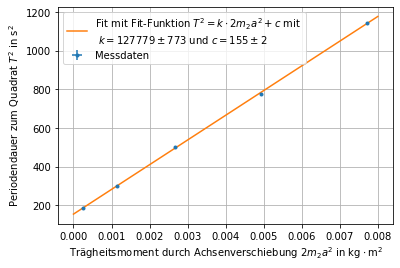

In [30]:
plt.figure()
plt.errorbar(2*m_hohl_scheibe*a_G_S_qua, T_G_S_qua, xerr = 2*m_hohl_scheibe*u_a_G_S_qua, yerr =  u_T_G_S_qua, fmt=".", label = "Messdaten")
werte = np.linspace(0, 0.008, 90)
plt.plot(werte, gerade(p , werte),label = "Fit mit Fit-Funktion $T^2 = k \cdot 2 m_2 a^2 +c$ mit \n $k = 127779 \pm 773$ und $c = 155 \pm 2$")
plt.grid()
plt.xlabel("Trägheitsmoment durch Achsenverschiebung $2 m_2 a^2$ in $\mathrm{kg\cdot m^2}$")
plt.ylabel("Periodendauer zum Quadrat $T^2$ in $\mathrm{s^2}$")
plt.legend()

In [31]:
# Berechnung des Direktionsmoment des Stabes
D_stern = (4*np.pi**2)/p[1]
u_D_stern = (4*np.pi**2*u_p[1])/p[1]**2
print("Das Direktionsmoment des Stabes lautet: " +str(D_stern) + " +/- " +str(u_D_stern))

Das Direktionsmoment des Stabes lautet: 0.00030895849086072746 +/- 1.8698878062260112e-06


In [36]:
# Berechnung des Trägheitsmoments J_1
J_1 = (T_0_S**2 * D_stern)/(4*np.pi**2)
u_J_1 = np.sqrt((T_0_S*D_stern *u_T_0_S/(2*np.pi**2))**2 + ((T_0_S**2 * u_D_stern)/(4*np.pi**2))**2)
print("Das Trägeheitsmoment J_1 lautet: " +str(J_1) + " +/- " + str(u_J_1))
print(u_J_1/J_1)

Das Trägeheitsmoment J_1 lautet: 0.0010780277467836667 +/- 1.3009964685216624e-05
0.012068302252917244


In [37]:
# Berechnung des Trägheitsmoments J_2
J_2 = (((p[0])/p[1]) - J_1)/2
u_J_2 = np.sqrt(((D_stern*u_p[0])/(8*np.pi**2))**2 + ((p[0]*u_D_stern)/(8*np.pi**2))**2 + (u_J_1/2)**2)
print("Das Trägheitsmoment J_2 lautet: " + str(J_2) + " +/- " +str(u_J_2))
print(u_J_2/J_2)

Das Trägheitsmoment J_2 lautet: 6.890348655017161e-05 +/- 1.06758151188732e-05
0.15493867804642478


In [34]:
# J_1 aus Theorie berechnet
J_1_theo = m_vol_zyl*(l_vol_zyl**2/12 + r_vol_zyl**2/4)
u_J_1_theo = np.sqrt((m_vol_zyl*l_vol_zyl*u_l_vol_zyl/6)**2 + (m_vol_zyl*r_vol_zyl*u_r_vol_zyl/2)**2) 
print("Das theoreisch errechnete Trägheitsmom J_1 lautet: " +str(J_1_theo) + " +/- " +str(u_J_1_theo))

Das theoreisch errechnete Trägheitsmom J_1 lautet: 0.0011368609538893331 +/- 1.854045899603159e-06


In [35]:
# J_2 aus Theorie berechnet
J_2_theo = m_hohl_scheibe*(l_hohl_scheibe**2/12 + (r_vol_zyl**2 + r_hohl_scheibe**2)/4)
u_J_2_theo = np.sqrt((m_hohl_scheibe*l_hohl_scheibe*u_l_hohl_scheibe/6)**2 + 
                     (m_hohl_scheibe*r_hohl_scheibe*u_r_hohl_scheibe/2)**2 + 
                     (m_hohl_scheibe*r_vol_zyl*u_r_vol_zyl/2)**2)
print("Das theoretische errechnete Trägheitsmoment J_2 lautet: " +str(J_2_theo) + " +/- " + str(u_J_2_theo))

Das theoretische errechnete Trägheitsmoment J_2 lautet: 5.6583103703000014e-05 +/- 3.717942869829964e-07
